# Planet imagery discovery

This notebook searches Planet Data API for imagery over the supplied area of interest and displays scene previews. It is a prototype data-discovery step for a later Streamlit dashboard. API credentials are requested at runtime and are not saved in the notebook.

## 1. Configure the connection

Planet Data API authenticates with the API key as the Basic Auth username and an empty password. The Planet account email/password is not used for this API workflow. Do not paste credentials into notebook cells or commit them.

In [1]:
! pip install planet

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyqrcode: filename=pyqrcode-1.2.1-py3-none-any.whl size=36267 sha256=fd436d044526973f83b7756626ab9c9609003c30bde2bc7846af0afbecdebad9
  Stored in directory: /Users/huss/Library/Caches/pip/wheels/cf/48/19/6be8e2ccebe999407bd355a8a22eddf84cb4b78b2a5c1b6a79
Successfully built pyqrcode
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [planet]


In [2]:
from getpass import getpass
from IPython.display import display, Markdown, Image
import requests
import pandas as pd

PLANET_API_KEY = getpass('Planet API key (input hidden): ')
if not PLANET_API_KEY.strip():
    raise ValueError('An API key is required to query Planet Data API.')

QUICK_SEARCH_URL = 'https://api.planet.com/data/v1/quick-search'
AOI = {
    'type': 'Polygon',
    'coordinates': [[
        [-52.4825, -6.8735], [-52.4825, -6.65775],
        [-52.26725, -6.65775], [-52.26725, -6.8735],
        [-52.4825, -6.8735],
    ]],
}


## 2. Search for the requested scenes

The search is restricted to the scene IDs listed for this task and the supplied area of interest.

In [3]:
# Restrict the search to the requested scene IDs and AOI.
REQUESTED_SCENE_IDS = ['20160816_125717_0e0d', '20160816_125718_0e0d', '20160816_125719_0e0d', '20160816_125816_0e0f', '20160816_125817_0e3a', '20160816_125817_0e0f', '20160816_125818_0e0f', '20160816_125819_0e3a', '20160816_125819_0e0f', '20160816_125820_0e3a', '20160816_125821_0e0f', '20160816_125821_0e3a', '20160816_125828_0e16', '20160816_125829_0e16', '20160816_125831_0e16', '20160816_125832_0e16', '20170622_130057_1026', '20170622_130058_1026', '20170622_130100_1026', '20170622_130101_1026', '20170622_130102_1026', '20170622_130148_1024', '20170622_130149_1024', '20170622_130151_1024', '20170622_130152_1024', '20170622_130153_1024', '20200709_131451_0e19', '20200709_131452_0e19', '20200709_131453_0e19', '20200709_131454_0e19', '20200709_131455_0e19', '20200709_134256_01_105c', '20200709_134257_89_105c', '20200709_134259_76_105c', '20210622_130016_76_2440', '20210622_130019_06_2440', '20210622_130021_37_2440', '20210622_130136_01_2429', '20210622_130138_31_2429', '20210622_135008_90_2419', '20210622_135011_38_2419', '20210622_135013_86_2419', '20220705_125542_65_242d', '20220705_125544_94_242d', '20220705_125547_24_242d', '20220705_132656_22_2482', '20220705_132658_50_2482', '20220705_132700_78_2482', '20230625_133059_08_2438', '20230625_133101_19_2438', '20230625_133103_30_2438', '20230625_133150_27_2495', '20230625_133152_41_2495', '20230625_133154_55_2495', '20240729_135811_12_24f5', '20240729_135813_35_24f5', '20240729_135815_59_24f5', '20240729_135949_11_24e0', '20240729_135951_35_24e0', '20240729_135953_59_24e0', '20250721_141153_79_251c', '20250721_141156_03_251c', '20250721_141640_52_252e', '20250721_141642_63_252e', '20250721_141644_73_252e', '20260802_135033_78_254d', '20260802_135035_88_254d', '20260802_135037_98_254d', '20260802_142722_38_253d', '20260802_142724_35_253d', '20260802_142726_32_253d', '20260802_143448_16_2409', '20260802_143449_97_2409', '20260802_143451_78_2409', '20260802_143617_56_24db', '20260802_143621_57_24db']
query = {
    'item_types': ['PSScene', 'SkySatCollect', 'PelicanScene'],
    'filter': {
        'type': 'AndFilter',
        'config': [
            {'type': 'GeometryFilter', 'field_name': 'geometry', 'config': AOI},
            {'type': 'StringInFilter', 'field_name': 'id', 'config': REQUESTED_SCENE_IDS},
        ],
    },
}

response = requests.post(
    QUICK_SEARCH_URL,
    json=query,
    auth=(PLANET_API_KEY, ''),
    timeout=(15, 60),
)
if response.status_code == 401:
    raise PermissionError('Planet rejected the API key (HTTP 401). Check the key and account access.')
response.raise_for_status()
payload = response.json()
features = payload.get('features', [])
print(f'Returned {len(features)} of {len(REQUESTED_SCENE_IDS)} requested scenes.')


Returned 250 scenes in this response.


## 3. Review scene metadata

In [ ]:
records = []
for feature in features:
    props = feature.get('properties', {})
    links = feature.get('_links', {})
    records.append({
        'id': feature.get('id'),
        'item_type': feature.get('item_type') or props.get('item_type'),
        'acquired': props.get('acquired'),
        'cloud_percent': props.get('cloud_percent'),
        'cloud_cover': props.get('cloud_cover'),
        'quality_category': props.get('quality_category'),
        'thumbnail': links.get('thumbnail'),
    })
scenes = pd.DataFrame(records)
if scenes.empty:
    display(Markdown('No scenes were returned for this AOI. Check account access, API key, and AOI coordinates.'))
else:
    display(scenes.drop(columns=['thumbnail']).sort_values('acquired', na_position='last').reset_index(drop=True))


,id,item_type,acquired,cloud_percent,cloud_cover,quality_category
0,20260813_143927_43_2523,PSScene,2026-08-13T14:39:27.430637Z,0,None,standard
1,20260813_143929_23_2523,PSScene,2026-08-13T14:39:29.234744Z,0,None,standard
2,20260813_143932_84_2523,PSScene,2026-08-13T14:39:32.842849Z,0,None,test
3,20260814_135433_87_2563,PSScene,2026-08-14T13:54:33.877031Z,0,None,standard
4,20260814_135435_99_2563,PSScene,2026-08-14T13:54:35.991015Z,0,None,standard
...,...,...,...,...,...,...
245,20261011_134822_21_256c,PSScene,2026-10-11T13:48:22.213059Z,38,None,test
246,20261011_134824_33_256c,PSScene,2026-10-11T13:48:24.33739Z,30,None,test
247,20261011_143243_30_252b,PSScene,2026-10-11T14:32:43.309353Z,37,None,test
248,20261011_143245_48_252b,PSScene,2026-10-11T14:32:45.484081Z,32,None,test


In [18]:
import pandas as pd

df = pd.DataFrame(records)
df["acquired"] = pd.to_datetime(df["acquired"])

# optional: drop the columns you don't need (cloud_cover is all None)
df = df[["id", "acquired", "cloud_percent", "quality_category"]]

print(df.head())
df.to_csv("all_images_values.csv", index=False)


                        id                         acquired  cloud_percent  \
0  20261011_143247_65_252b 2026-10-11 14:32:47.658754+00:00             26   
1  20261011_143245_48_252b 2026-10-11 14:32:45.484081+00:00             32   
2  20261011_143243_30_252b 2026-10-11 14:32:43.309353+00:00             37   
3  20261011_134822_21_256c 2026-10-11 13:48:22.213059+00:00             38   
4  20261011_134820_08_256c 2026-10-11 13:48:20.088727+00:00             47   

  quality_category  
0             test  
1             test  
2             test  
3             test  
4             test  


## 4. Display the requested previews

Only the requested scene IDs are displayed. Each image title includes its acquisition date and time when Planet returns that metadata; otherwise the timestamp embedded in the scene ID is used.

**20261008_135338_04_2528** — 2026-10-08T13:53:38.046599Z | PSScene

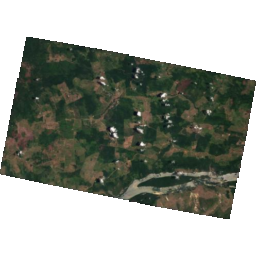

**20261009_143424_28_252a** — 2026-10-09T14:34:24.28928Z | PSScene

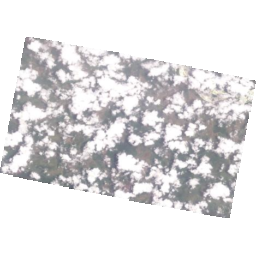

**20261009_143426_25_252a** — 2026-10-09T14:34:26.257965Z | PSScene

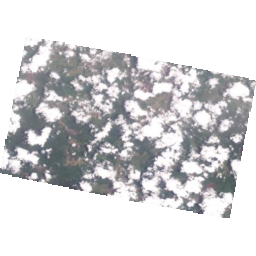

**20261009_143428_22_252a** — 2026-10-09T14:34:28.226594Z | PSScene

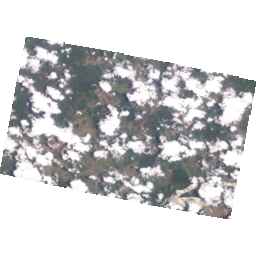

**20261010_134730_93_2544** — 2026-10-10T13:47:30.936204Z | PSScene

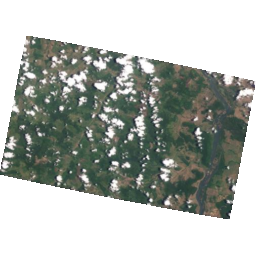

**20261010_134733_28_2544** — 2026-10-10T13:47:33.286642Z | PSScene

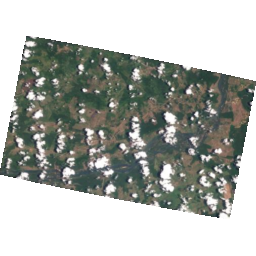

**20261011_134820_08_256c** — 2026-10-11T13:48:20.088727Z | PSScene

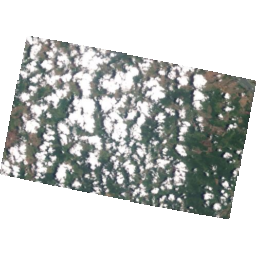

**20261011_134822_21_256c** — 2026-10-11T13:48:22.213059Z | PSScene

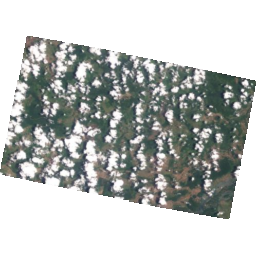

**20261011_134824_33_256c** — 2026-10-11T13:48:24.33739Z | PSScene

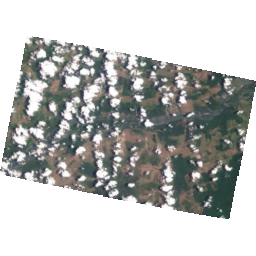

**20261011_143243_30_252b** — 2026-10-11T14:32:43.309353Z | PSScene

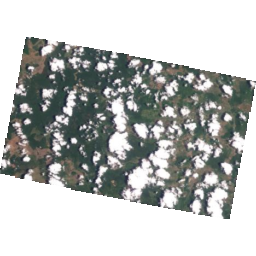

**20261011_143245_48_252b** — 2026-10-11T14:32:45.484081Z | PSScene

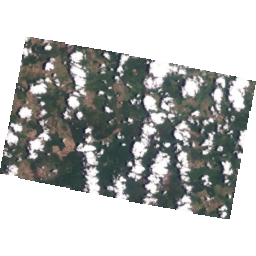

**20261011_143247_65_252b** — 2026-10-11T14:32:47.658754Z | PSScene

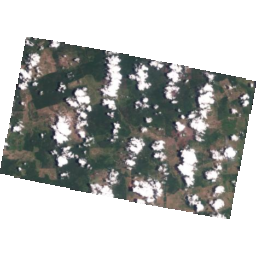

In [19]:
# Show only requested IDs, keeping the requested order.
if not scenes.empty:
    selected = scenes.set_index('id', drop=False)
    found_ids = [scene_id for scene_id in REQUESTED_SCENE_IDS if scene_id in selected.index]
    missing_ids = [scene_id for scene_id in REQUESTED_SCENE_IDS if scene_id not in selected.index]
    if missing_ids:
        print(f'{len(missing_ids)} requested IDs were not returned by this search; they may be unavailable to this account or outside the AOI.')
    for scene_id in found_ids:
        row = selected.loc[scene_id]
        if isinstance(row, pd.DataFrame):
            row = row.iloc[0]
        if pd.isna(row['thumbnail']) or not row['thumbnail']:
            print(f'Preview unavailable for {scene_id}: no thumbnail link was returned.')
            continue
        acquired = pd.to_datetime(row['acquired'], utc=True, errors='coerce')
        if pd.notna(acquired):
            title_time = acquired.strftime('%Y-%m-%d %H:%M:%S UTC')
        else:
            # Scene IDs start with YYYYMMDD_HHMMSS; use that as a display fallback.
            try:
                title_time = pd.to_datetime(scene_id[:15], format='%Y%m%d_%H%M%S').strftime('%Y-%m-%d %H:%M:%S') + ' (UTC, from scene ID)'
            except ValueError:
                title_time = 'Acquisition time unavailable'
        display(Markdown(f"### {title_time} — {scene_id}"))
        try:
            thumb = requests.get(row['thumbnail'], auth=(PLANET_API_KEY, ''), timeout=(15, 60))
            thumb.raise_for_status()
            display(Image(data=thumb.content, width=600))
        except requests.RequestException as exc:
            print(f'Preview unavailable for {scene_id}: {exc}')


## 5. Scene count by cloud percentage

This bar chart counts the scenes in `records` at each returned `cloud_percent` value. Missing cloud percentages are shown as their own category.


In [ ]:
import matplotlib.pyplot as plt

records_df = pd.DataFrame(records)
if records_df.empty or 'cloud_percent' not in records_df:
    print('No scene records are available to chart.')
else:
    cloud_values = pd.to_numeric(records_df['cloud_percent'], errors='coerce')
    cloud_counts = cloud_values.value_counts().sort_index()
    if cloud_values.isna().any():
        cloud_counts.loc['Unknown'] = cloud_values.isna().sum()
    fig, ax = plt.subplots(figsize=(12, 5))
    cloud_counts.plot(kind='bar', ax=ax, color='#2878B5')
    ax.set_title('Number of requested scenes by cloud percentage')
    ax.set_xlabel('Cloud percentage')
    ax.set_ylabel('Number of scenes')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', linestyle=':', alpha=0.5)
    fig.tight_layout()
    plt.show()


## 6. Combine same-day rasters and clip to the GeoJSON AOI

This step requires full-resolution GeoTIFF assets saved locally in `downloaded_geotiffs/`, with each filename containing its Planet scene ID (for example, `20160816_125717_0e0d.tif`). The thumbnail previews from section 4 are not suitable inputs. Scenes are grouped by the date in `records`, mosaicked for each day, and clipped to the AOI polygon below. Inputs for a single day must have compatible CRS, band count, and pixel resolution (as expected for scenes covering this small area).


In [ ]:
%pip install rasterio


In [ ]:
from pathlib import Path
from collections import defaultdict
import rasterio
from rasterio.io import MemoryFile
from rasterio.merge import merge
from rasterio.mask import mask
from rasterio.warp import transform_geom

# Feature supplied for the evaluation; coordinates are GeoJSON longitude/latitude (EPSG:4326).
AOI_GEOJSON = {
    "type": "Feature",
    "id": "0",
    "properties": {
        "from": "2015-01-01",
        "to": "2017-01-01",
        "center_x": -52.37487500000001,
        "center_y": -6.765613263405268,
        "area_sqkm": 568.0,
        "collection_id": "f3312c82-edea-42a1-8c9d-ada86ddcc857",
        "geolocation": "Pará, North Region, Brazil",
    },
    "geometry": {
        "type": "Polygon",
        "coordinates": [[
            [-52.4825, -6.8735],
            [-52.4825, -6.65775],
            [-52.267250000000004, -6.65775],
            [-52.267250000000004, -6.8735],
            [-52.4825, -6.8735],
        ]],
    },
}

INPUT_RASTER_DIR = Path('downloaded_geotiffs')
OUTPUT_MOSAIC_DIR = Path('daily_mosaics_clipped')
OUTPUT_MOSAIC_DIR.mkdir(parents=True, exist_ok=True)

# Index scene IDs by acquisition day using the metadata already fetched from Planet.
scenes_by_day = defaultdict(list)
for record in records:
    if not record.get('id') or not record.get('acquired'):
        continue
    acquired_day = pd.to_datetime(record['acquired'], utc=True, errors='coerce')
    if pd.notna(acquired_day):
        scenes_by_day[acquired_day.strftime('%Y-%m-%d')].append(record['id'])

raster_paths = list(INPUT_RASTER_DIR.glob('*.tif')) + list(INPUT_RASTER_DIR.glob('*.tiff'))
if not raster_paths:
    print(f'No GeoTIFFs found in {INPUT_RASTER_DIR.resolve()}. Download the analytic assets before running this section.')
else:
    processed_days = 0
    for day, scene_ids in sorted(scenes_by_day.items()):
        # Match local asset filenames to the Planet scene IDs for this date.
        day_paths = [path for path in raster_paths if any(scene_id in path.stem for scene_id in scene_ids)]
        if not day_paths:
            print(f'{day}: no matching GeoTIFFs found; skipping.')
            continue

        from contextlib import ExitStack
        with ExitStack() as stack:
            datasets = [stack.enter_context(rasterio.open(path)) for path in day_paths]
            crs_set = {dataset.crs for dataset in datasets}
            band_counts = {dataset.count for dataset in datasets}
            if len(crs_set) != 1 or len(band_counts) != 1:
                print(f'{day}: inputs have mismatched CRS or band counts; reproject/standardize them before mosaicking.')
                continue

            mosaic, mosaic_transform = merge(datasets)
            profile = datasets[0].profile.copy()
            profile.update(
                driver='GTiff', height=mosaic.shape[1], width=mosaic.shape[2],
                transform=mosaic_transform, count=mosaic.shape[0], compress='deflate'
            )
            target_geometry = transform_geom('EPSG:4326', datasets[0].crs, AOI_GEOJSON['geometry'])

            # Use an in-memory GeoTIFF so the clip uses the mosaic's georeferencing.
            with MemoryFile() as memory_file:
                with memory_file.open(**profile) as mosaic_dataset:
                    mosaic_dataset.write(mosaic)
                with memory_file.open() as mosaic_dataset:
                    clipped, clipped_transform = mask(
                        mosaic_dataset, [target_geometry], crop=True, nodata=profile.get('nodata')
                    )
                    clipped_profile = mosaic_dataset.profile.copy()
                    clipped_profile.update(
                        height=clipped.shape[1], width=clipped.shape[2],
                        transform=clipped_transform, compress='deflate'
                    )
                    output_path = OUTPUT_MOSAIC_DIR / f'{day}_mosaic_clipped.tif'
                    with rasterio.open(output_path, 'w', **clipped_profile) as output:
                        output.write(clipped)
        processed_days += 1
        print(f'{day}: mosaicked {len(day_paths)} scene(s) and saved {output_path}')
    print(f'Finished: wrote {processed_days} daily clipped mosaic(s) to {OUTPUT_MOSAIC_DIR.resolve()}')


## Next step: Streamlit

Once the scene previews and filters are validated, move the search and display logic into a Streamlit app. Keep the API key in an environment variable or Streamlit secrets (for local development, `.streamlit/secrets.toml` should be excluded from version control). Add pagination, bounded retries, and asset activation/download handling before scaling beyond exploratory use.